# CSCI 3003 - Data Visualization

## Lab 1: Opening, Inspecting, and Plotting Data

**Name:** Steve Tatsiguia
**Date:** 2026-09-01
**Version:** Student notebook


## Purpose and learning objectives

This lab gives you a careful first workflow for working with a data file. By the end, you should be able to:

- Explain where Python looks for a file.
- Load a CSV file into a pandas DataFrame.
- Inspect rows, columns, data types, and missing values.
- Select columns and make a simple scatter plot.
- Rename long survey questions with descriptive `snake_case` names.
- Pose and investigate an open-ended question using de-identified class survey data.

We will complete Parts I-IV together. Part V is open-ended practice.


## I. Import the packages

A **package** is a collection of code written for a particular purpose. We will use:

- `pandas` to open and inspect tables;
- `matplotlib.pyplot` to make a plot; and
- `Path` to show clearly where Python is looking for files.

The word after `as` is a short nickname. For example, `pd` is the conventional nickname for pandas.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

## II. Find and load the practice dataset

For practice, let's use the `loan50.csv` dataset, which contains a random sample of 50 loans offered through the Lending Club.

How do we load this data? First we need to know where to look!

The **working directory** is the folder where Python starts looking for relative file paths. `Path.cwd()` means “show the current working directory.” The empty parentheses tell Python to run the function.

Run the next cell and compare its output with the folder open in the VS Code Explorer.


In [ ]:
working_directory = Path.cwd()
working_directory 

WindowsPath('c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/01-labs')

The course folder should be open in VS Code. If the output above ends with `01-labs`, use the Explorer to open the full course folder before continuing.

A **relative path** gives directions starting from the working directory. Here, `01-labs/loan50.csv` means “open the `01-labs` folder, then find `loan50.csv`.”


In [4]:
loan_file = Path("c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/01-labs/loan50.csv")

# exists() checks whether a file is present at this path.
loan_file.exists()

True

The previous cell should display `True`. If it displays `False`:

- Read the working-directory output above.
- In the VS Code Explorer, check that `loan50.csv` is inside `01-labs`.
- Open the full course folder in VS Code and run the cells again.

Do not run the next cell until the path check displays `True`.

`pd.read_csv(...)` is a pandas function that reads a comma-separated-values file. The file path goes inside the parentheses. The result is stored in a pandas **DataFrame**, which is a table with rows and columns.


In [5]:
loans = pd.read_csv(loan_file)

# head() displays the first five rows unless we provide a different number.
loans.head()

,state,emp_length,term,homeownership,annual_income,verified_income,debt_to_income,total_credit_limit,total_credit_utilized,num_cc_carrying_balance,loan_purpose,loan_amount,grade,interest_rate,public_record_bankrupt,loan_status,has_second_income,total_income
0,NJ,3.0,60,rent,59000,Not Verified,0.557525,95131,32894,8,debt_consolidation,22000,B,10.90,0,Current,False,59000
1,CA,10.0,36,rent,60000,Not Verified,1.305683,51929,78341,2,credit_card,6000,B,9.92,1,Current,False,60000
2,SC,NaN,36,mortgage,75000,Verified,1.056280,301373,79221,14,debt_consolidation,25000,E,26.30,0,Current,False,75000
3,CA,0.0,36,rent,75000,Not Verified,0.574347,59890,43076,10,credit_card,6000,B,9.92,0,Current,False,75000
4,OH,4.0,60,mortgage,254000,Not Verified,0.238150,422619,60490,2,home_improvement,25000,B,9.43,0,Current,False,254000


**Question 1:** In one sentence, explain how the working directory and relative path combine to locate `loan50.csv`.

**Answer:** Working directory help us find where we located and where the files located, then we used that path to open the file and load it


## III. Inspect the table

Before analyzing a dataset, learn what it contains.

- `.shape` reports `(number of rows, number of columns)`. It is an attribute, so it does not use parentheses.
- `.columns` contains the column names.
- `.info()` displays column names, non-missing counts, and data types.


In [6]:
loans.shape

(50, 18)

In [7]:
loans.columns

Index(['state', 'emp_length', 'term', 'homeownership', 'annual_income',
       'verified_income', 'debt_to_income', 'total_credit_limit',
       'total_credit_utilized', 'num_cc_carrying_balance', 'loan_purpose',
       'loan_amount', 'grade', 'interest_rate', 'public_record_bankrupt',
       'loan_status', 'has_second_income', 'total_income'],
      dtype='str')

In [8]:
loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   state                    50 non-null     str    
 1   emp_length               48 non-null     float64
 2   term                     50 non-null     int64  
 3   homeownership            50 non-null     str    
 4   annual_income            50 non-null     int64  
 5   verified_income          50 non-null     str    
 6   debt_to_income           50 non-null     float64
 7   total_credit_limit       50 non-null     int64  
 8   total_credit_utilized    50 non-null     int64  
 9   num_cc_carrying_balance  50 non-null     int64  
 10  loan_purpose             50 non-null     str    
 11  loan_amount              50 non-null     int64  
 12  grade                    50 non-null     str    
 13  interest_rate            50 non-null     float64
 14  public_record_bankrupt   50 non-null   

**Question 2:** How many rows and columns are in the table? What does one row appear to represent? Name two columns that contain numbers.

**Answer:** There are 50 rows and 18 columns and a row represents one case. colums containing numbers: term, total_income


### Check missing values

Missing values are blank or unavailable entries.

- `.isna()` checks every entry and returns `True` when a value is missing.
- `.sum()` counts the `True` values in each column.

The two functions are written together as `.isna().sum()` because the second function acts on the result of the first.


In [9]:
missing_values = loans.isna().sum()
missing_values

state                      0
emp_length                 2
term                       0
homeownership              0
annual_income              0
verified_income            0
debt_to_income             0
total_credit_limit         0
total_credit_utilized      0
num_cc_carrying_balance    0
loan_purpose               0
loan_amount                0
grade                      0
interest_rate              0
public_record_bankrupt     0
loan_status                0
has_second_income          0
total_income               0
dtype: int64

**Question 3:** Which column or columns contain missing values? How many values are missing in each?

**Answer:** emp_length is the only column missing values and it's missing two values


### Select a few columns

Square brackets select data from a DataFrame. One column name selects one column. A list of column names selects a smaller table. Notice the two pairs of square brackets below: the inner pair creates the list, and the outer pair selects those columns.


In [10]:
loan_amounts = loans["loan_amount"]
loan_amounts.head()

0    22000
1     6000
2    25000
3     6000
4    25000
Name: loan_amount, dtype: int64

In [11]:
selected_columns = loans[["annual_income", "loan_amount", "interest_rate"]]
selected_columns.head()

,annual_income,loan_amount,interest_rate
0,59000,22000,10.90
1,60000,6000,9.92
2,75000,25000,26.30
3,75000,6000,9.92
4,254000,25000,9.43


**Question 4:** What information is retained in `selected_columns`? What information from the original table is no longer displayed?

**Answer:**  Informations from the columns that was retained. What is missing are all the other columns not retained.


## IV. Make a first scatter plot

A scatter plot shows the relationship between two numerical variables. Each dot represents one row.

`plt.scatter(x, y)` draws the plot. The first argument supplies horizontal-axis values, and the second supplies vertical-axis values. The other functions add readable labels and a title.


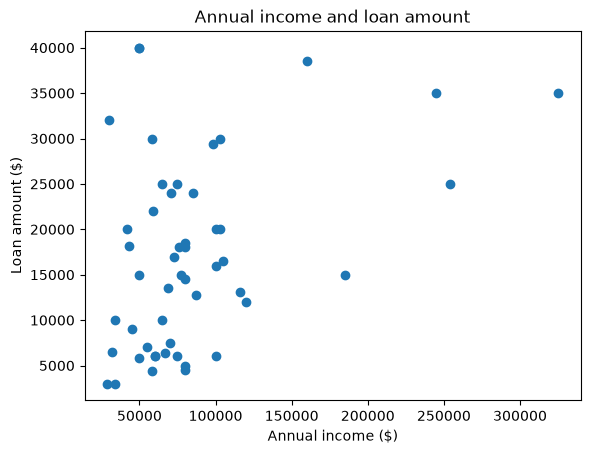

In [12]:
plt.scatter(loans["annual_income"], loans["loan_amount"])
plt.xlabel("Annual income ($)")
plt.ylabel("Loan amount ($)")
plt.title("Annual income and loan amount")
plt.show()

**Question 5:** Describe what the axes and one dot represent. Then describe one pattern or unusual point you notice without claiming that one variable causes the other.

**Answer:** y-axis represent the loan amount and the x-axis represent annual income. The pattern shows that the lower your annaual income is the more likely you are of asking a loan but there are always outlires with a point making over 300000 a year and asking for a 30000 dollars loan


## V. Open-ended practice: our class survey

Use only the instructor-provided survey file. Do not attempt to identify classmates, and do not display the `Id`, time, email, or name columns. Avoid displaying small demographic categories that could identify a student.

First, use the same path-checking process as above.


In [13]:
survey_file = Path("student_survey_fall2026.csv")
survey_file.exists()

True

The current survey export comes from Microsoft Forms and uses Windows text encoding. The `encoding="cp1252"` argument tells pandas how to translate the file's characters. This is an example of a function argument written as `name=value`.


In [14]:
survey_raw = pd.read_csv(survey_file, encoding="cp1252")
survey_raw.shape

(12, 14)

### Give the survey columns useful names

Long survey questions are awkward to type in code. We will use **snake case** (`snake_case`) for new variable names in this course:

- begin with a lowercase word;
- separate words with underscores;
- use no spaces or other punctuation; and
- choose a short name that still communicates the variable's meaning.

For example, `graph_confidence` is clearer than `question14` and easier to type than the full question.

`.rename(columns=...)` changes column names. The dictionary inside the parentheses pairs each old name with its new name. The example below renames every question and then selects only de-identified columns.


In [15]:
survey_raw.columns[1]

'How do you describe your gender?'

In [16]:
survey_column_names = {
    survey_raw.columns[0]: "age_years",
    survey_raw.columns[1]: "gender_identity",
    survey_raw.columns[2]: "intended_major",
    survey_raw.columns[3]: "introversion_extroversion",
    survey_raw.columns[4]: "preferred_study_setting",
    survey_raw.columns[5]: "favorite_ice_cream_flavor",
    survey_raw.columns[6]: "completed_statistics",
    survey_raw.columns[7]: "statistics_completion_year",
    survey_raw.columns[8]: "statistics_experience",
    survey_raw.columns[9]: "graph_confidence",
    survey_raw.columns[10]: "programming_experience",
    survey_raw.columns[11]: "programming_languages",
    survey_raw.columns[12]: "vscode_experience",
    survey_raw.columns[13]: "troubleshooting_confidence",
}

survey = survey_raw.rename(columns=survey_column_names)
survey.columns

Index(['age_years', 'gender_identity', 'intended_major',
       'introversion_extroversion', 'preferred_study_setting',
       'favorite_ice_cream_flavor', 'completed_statistics',
       'statistics_completion_year', 'statistics_experience',
       'graph_confidence', 'programming_experience', 'programming_languages',
       'vscode_experience', 'troubleshooting_confidence'],
      dtype='str')

### Investigate a question of your choice

Choose a question that can be answered with this de-identified survey. Your question may use one variable or compare two variables. Decide what inspection, summary, or plot would help.

**Question 6:** Does your age has an effect in your flavour of ice cream

**Your investigation question:** I would have to compare two columns in a dot plot to see if there is a correlation

In the next cell, remove the `#` comment symbols only from the lines you want to use. Replace the example column name with the variable you chose. You may add more cells.


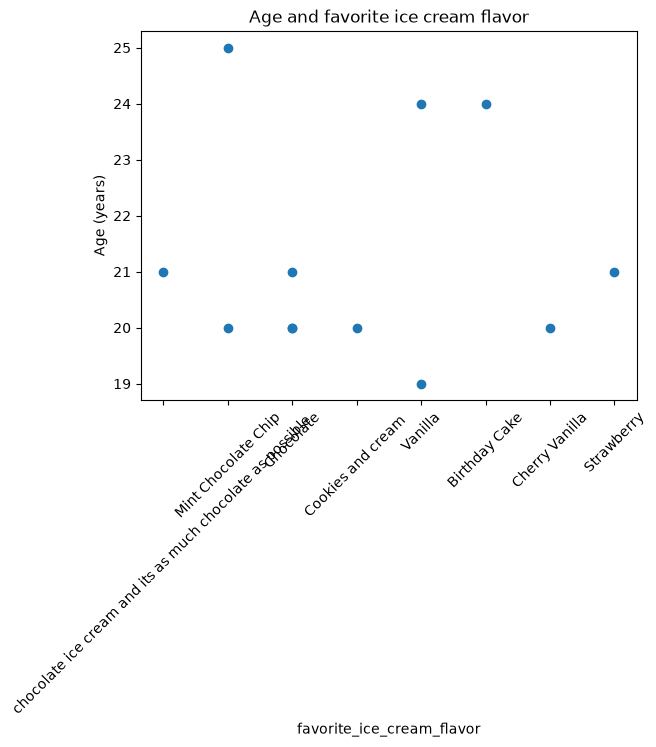

In [20]:
survey.head()
survey["age_years"].value_counts()
survey["favorite_ice_cream_flavor"].value_counts()

plt.scatter(survey["favorite_ice_cream_flavor"], survey["age_years"])
plt.xlabel("favorite_ice_cream_flavor")
plt.ylabel("Age (years)")
plt.title("Age and favorite ice cream flavor")
plt.xticks(rotation=45)
plt.show()

**Answer to Question 6:** Nope there is no correlation and conclution is that your age and favorite ice cream have no correlation


## VI. Submission check

Before exporting:

- Add your name and date, and complete Questions 1-6.
- Check that survey outputs protect student privacy.
- Restart the kernel, run all cells, and resolve any errors.
- Export to HTML and confirm that all work is visible.
